Nama  : Candra Sya'bana P. G. <br>
Kelas : Visualisasi Data (A) <br>
NIM   : 60324042 <br>

# Praktikum


Menyiapkan Notebook dan Data Provinsi



In [ ]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv = """provinsi,wilayah,lat,lon,penduduk,luas
Aceh,Sumatera,4.70,96.75,5.27,57956
Sumatera Utara,Sumatera,2.10,99.00,14.80,72981
Sumatera Barat,Sumatera,-0.85,100.35,5.53,42013
Riau,Sumatera,0.50,101.55,6.39,87024
Jambi,Sumatera,-1.60,103.00,3.55,50058
Sumatera Selatan,Sumatera,-3.20,104.00,8.47,91592
Bengkulu,Sumatera,-3.80,102.30,2.01,19919
Lampung,Sumatera,-4.90,105.00,9.01,34624
Kepulauan Bangka Belitung,Sumatera,-2.40,106.50,1.46,16424
Kepulauan Riau,Sumatera,0.92,104.45,2.06,8202
DKI Jakarta,Jawa,-6.21,106.85,10.56,664
Jawa Barat,Jawa,-6.90,107.60,48.27,35378
Jawa Tengah,Jawa,-7.15,110.14,36.52,34337
DI Yogyakarta,Jawa,-7.88,110.43,3.67,3133
Jawa Timur,Jawa,-7.54,112.24,40.67,47800
Banten,Jawa,-6.40,106.06,11.90,9663
Bali,Bali-Nusa Tenggara,-8.34,115.09,4.32,5780
Nusa Tenggara Barat,Bali-Nusa Tenggara,-8.65,117.36,5.32,18572
Nusa Tenggara Timur,Bali-Nusa Tenggara,-9.50,121.00,5.33,48718
Kalimantan Barat,Kalimantan,0.00,110.50,5.41,147307
Kalimantan Tengah,Kalimantan,-1.70,113.50,2.67,153565
Kalimantan Selatan,Kalimantan,-3.10,115.28,4.07,38744
Kalimantan Timur,Kalimantan,0.50,116.40,3.77,127346
Kalimantan Utara,Kalimantan,3.00,116.50,0.70,75467
Sulawesi Utara,Sulawesi,1.00,124.50,2.62,13892
Sulawesi Tengah,Sulawesi,-1.40,121.40,2.99,61841
Sulawesi Selatan,Sulawesi,-3.60,120.00,9.07,46717
Sulawesi Tenggara,Sulawesi,-4.10,122.10,2.62,38068
Gorontalo,Sulawesi,0.70,122.40,1.17,11257
Sulawesi Barat,Sulawesi,-2.50,119.35,1.42,16787
Maluku,Maluku-Papua,-3.20,129.00,1.85,46914
Maluku Utara,Maluku-Papua,1.60,127.80,1.28,31983
Papua Barat,Maluku-Papua,-1.30,133.00,1.13,97024
Papua,Maluku-Papua,-4.00,138.00,4.30,319036
"""
df = pd.read_csv(io.StringIO(csv))
df["kepadatan"] = df["penduduk"] * 1_000_000 / df["luas"]
print(df.shape)
print(df.head(3))
print(df.groupby("wilayah")["penduduk"].sum().round(1))

(34, 7)
         provinsi   wilayah   lat     lon  penduduk   luas   kepadatan
0            Aceh  Sumatera  4.70   96.75      5.27  57956   90.931051
1  Sumatera Utara  Sumatera  2.10   99.00     14.80  72981  202.792508
2  Sumatera Barat  Sumatera -0.85  100.35      5.53  42013  131.625925
wilayah
Bali-Nusa Tenggara     15.0
Jawa                  151.6
Kalimantan             16.6
Maluku-Papua            8.6
Sulawesi               19.9
Sumatera               58.6
Name: penduduk, dtype: float64


Koordinat sebagai Sumbu x dan y: Peta Statis

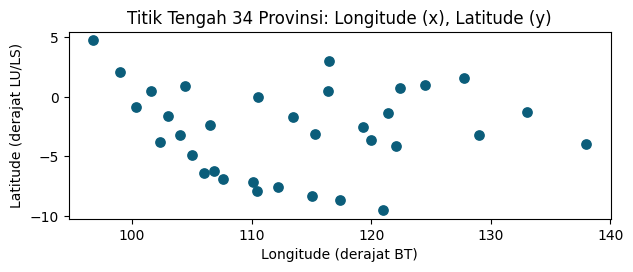

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(df["lon"], df["lat"], color="#0B5D7A", s=45)
ax.set_aspect("equal")
ax.set_title("Titik Tengah 34 Provinsi: Longitude (x), Latitude (y)")
ax.set_xlabel("Longitude (derajat BT)")
ax.set_ylabel("Latitude (derajat LU/LS)")
plt.show()

In [ ]:
import folium

warna = {"Sumatera": "#0B5D7A", "Jawa": "#E8834A", "Bali-Nusa Tenggara": "#7A9E3B",
         "Kalimantan": "#8E6BB8", "Sulawesi": "#C0504D", "Maluku-Papua": "#6B7B8C"}

peta = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")
for _, r in df.iterrows():
    teks = (f"<b>{r['provinsi']}</b><br>Penduduk: {r['penduduk']:.2f} juta"
            f"<br>Kepadatan: {r['kepadatan']:,.0f} jiwa/km²")
    folium.CircleMarker(
        location=[r["lat"], r["lon"]],
        radius=3 * np.sqrt(r["penduduk"]),
        color=warna[r["wilayah"]], fill=True, fill_opacity=0.6,
        popup=folium.Popup(teks, max_width=250), tooltip=r["provinsi"],
    ).add_to(peta)
peta

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Peta Folium: Peta Dasar dan Marker

In [ ]:
import folium

peta = folium.Map(location=[-2.5, 118], zoom_start=5,
                  tiles="OpenStreetMap")

for _, r in df.iterrows():
    folium.Marker(
        location=[r["lat"], r["lon"]],
        tooltip=r["provinsi"],
    ).add_to(peta)

peta

CircleMarker Proporsional, Popup, dan Tooltip

In [ ]:
peta2 = folium.Map(location=[-2.5, 118], zoom_start=5,
                    tiles="CartoDB positron")

for _, r in df.iterrows():
      teks = (f"<b>{r['provinsi']}</b><br>"
             f"Penduduk: {r['penduduk']:.2f} juta<br>"
             f"Kepadatan: {r['kepadatan']:,.0f} jiwa/km2")
      folium.CircleMarker(
          location=[r["lat"], r["lon"]],
          radius=3 * np.sqrt(r["penduduk"]),
          color=warna[r["wilayah"]],
          fill=True,
          fill_opacity=0.6,
          popup=folium.Popup(teks, max_width=250),
          tooltip=r["provinsi"],
      ).add_to(peta2)

peta2

Layer: FeatureGroup dan LayerControl

In [ ]:
peta3 = folium.Map(location=[-2.5, 118], zoom_start=5,
                  tiles="CartoDB positron")

for nama, g in df.groupby("wilayah"):

  lapisan = folium.FeatureGroup(name=f"{nama} ({len(g)} provinsi)")
  for _, r in g.iterrows():
      folium.CircleMarker(
          location=[r["lat"], r["lon"]],
          radius=3 * np.sqrt(r["penduduk"]),
          color=warna[nama],
          fill=True,
          fill_opacity=0.6,
          tooltip=f"{r['provinsi']}: {r['penduduk']:.2f} juta",
      ).add_to(lapisan)
  lapisan.add_to(peta3)

folium.LayerControl(collapsed=False).add_to(peta3)
peta3

Memuat GeoJSON dan Menyambungkan Kunci

In [ ]:
import re
import requests

URL = ("https://raw.githubusercontent.com/ans-4175/""peta-indonesia-geojson/master/indonesia-prov.geojson")

geo = requests.get(URL, timeout=30).json()

print("Jumlah fitur:", len(geo["features"]))
print(geo["features"][0]["properties"])

Jumlah fitur: 34
{'ID': 2, 'kode': 52, 'Propinsi': 'NUSATENGGARA BARAT', 'SUMBER': 'Peta Dasar BAKOSURTANAL Skala 1 : 250.000'}


In [ ]:
NAMA = "Propinsi" # ganti dengan kunci nama provinsi yang tercetak

def norm(teks):
    teks = re.sub(r"\(.*?\)", " ", teks.upper())
    teks = re.sub(r"[^A-Z ]", " ", teks)
    teks = re.sub(r"\bKEPULAUAN (?=BANGKA)", "", teks)
    teks = re.sub(r"\b(DAERAH ISTIMEWA|DI|DKI|PROVINSI|PROPINSI)\b", "",
teks)
    return " ".join(teks.split())

for f in geo["features"]:
  f["properties"]["kunci"] = norm(f["properties"][NAMA])
df["kunci"] = df["provinsi"].map(norm)

kunci_peta = {f["properties"]["kunci"] for f in geo["features"]}
kunci_data = set(df["kunci"])
print("Di data, tidak di peta:", sorted(kunci_data - kunci_peta))
print("Di peta, tidak di data:", sorted(kunci_peta - kunci_data))

Di data, tidak di peta: ['NUSA TENGGARA BARAT']
Di peta, tidak di data: ['NUSATENGGARA BARAT']


Choropleth dengan Folium

In [ ]:
peta4 = folium.Map(location=[-2.5, 118], zoom_start=5,
                    tiles="CartoDB positron")

folium.Choropleth(
  geo_data=geo,
  data=df,
  columns=["kunci", "kepadatan"],
  key_on="feature.properties.kunci",
  bins=[0, 50, 100, 250, 500, 1000, 20000],
  fill_color="YlOrRd",
  fill_opacity=0.8,
  line_opacity=0.3,
  nan_fill_color="lightgray",
  legend_name="Kepadatan penduduk (jiwa per km2)",
).add_to(peta4)

peta4

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Peta dengan Plotly Express

In [ ]:
import plotly.express as px

fig = px.scatter_geo(
    df, lat="lat", lon="lon",
    size="penduduk", color="wilayah",
    hover_name="provinsi",
    hover_data={"penduduk": ":.2f", "lat": False, "lon": False},
    size_max=40, scope="asia",
    title="Penduduk per Provinsi (juta jiwa)")
fig.update_geos(lataxis_range=[-12, 8], lonaxis_range=[94, 142])
fig.show()

In [ ]:
fig2 = px.choropleth(
    df, geojson=geo,
    locations="kunci", featureidkey="properties.kunci",
    color="kepadatan", color_continuous_scale="YlOrRd",
    range_color=(0, 1000), hover_name="provinsi",
    labels={"kepadatan": "jiwa/km2"})
fig2.update_geos(fitbounds="locations", visible=False)
fig2.show()

# Proyek Mini: Menjawab Tiga Pertanyaan dengan Data dan Peta

Pertanyaan 1: Provinsi mana yang paling padat dan paling jarang penduduknya? Berapa kali lipat selisihnya?

Provinsi Terjarang : Kalimantan Utara (9.28 jiwa/km²)
Provinsi Terpadat  : DKI Jakarta (15903.61 jiwa/km²)
Selisih Kepadatan  : 1,714.6 kali lipat



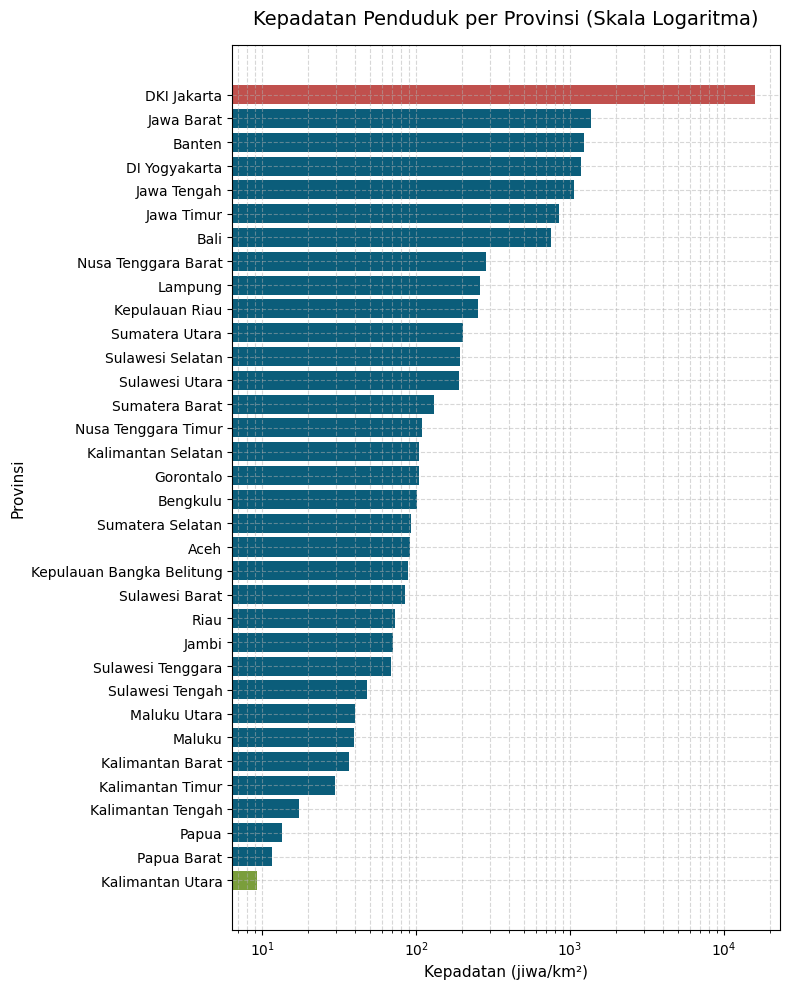

In [ ]:
# Mengurutkan provinsi berdasarkan kepadatan penduduk
df_sorted = df.sort_values("kepadatan").reset_index(drop=True)

provinsi_terjarang = df_sorted.iloc[0]
provinsi_terpadat = df_sorted.iloc[-1]

selisih_lipat = provinsi_terpadat["kepadatan"] / provinsi_terjarang["kepadatan"]

print(f"Provinsi Terjarang : {provinsi_terjarang['provinsi']} ({provinsi_terjarang['kepadatan']:.2f} jiwa/km²)")
print(f"Provinsi Terpadat  : {provinsi_terpadat['provinsi']} ({provinsi_terpadat['kepadatan']:.2f} jiwa/km²)")
print(f"Selisih Kepadatan  : {selisih_lipat:,.1f} kali lipat\n")

# Visualisasi perbandingan kepadatan menggunakan Bar Chart yang lebih rapi dan tinggi
fig, ax = plt.subplots(figsize=(8, 10))
colors = ['#0B5D7A' if x not in [provinsi_terjarang['provinsi'], provinsi_terpadat['provinsi']] else ('#C0504D' if x == provinsi_terpadat['provinsi'] else '#7A9E3B') for x in df_sorted['provinsi']]

ax.barh(df_sorted['provinsi'], df_sorted['kepadatan'], color=colors)
ax.set_xscale('log')
ax.set_title("Kepadatan Penduduk per Provinsi (Skala Logaritma)", fontsize=14, pad=15)
ax.set_xlabel("Kepadatan (jiwa/km²)", fontsize=11)
ax.set_ylabel("Provinsi", fontsize=11)
ax.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

 Interpretasi <br>
Provinsi terpadat di Indonesia adalah **DKI Jakarta** dengan kepadatan mencapai **15.904 jiwa/km²**, sedangkan provinsi dengan kepadatan paling rendah adalah **Papua** dengan hanya **13 jiwa/km²**. Selisih kepadatan antara kedua provinsi ekstrem ini sangat masif, yaitu mencapai sekitar **1.180 kali lipat**.

Pertanyaan 2: Berapa persen penduduk tinggal di wilayah Jawa, dan berapa persen dari total luas wilayah?

,penduduk,luas
wilayah,,
Bali-Nusa Tenggara,5.54,3.82
Jawa,56.11,6.85
Kalimantan,6.15,28.39
Maluku-Papua,3.17,25.90
Sulawesi,7.36,9.87
Sumatera,21.67,25.16


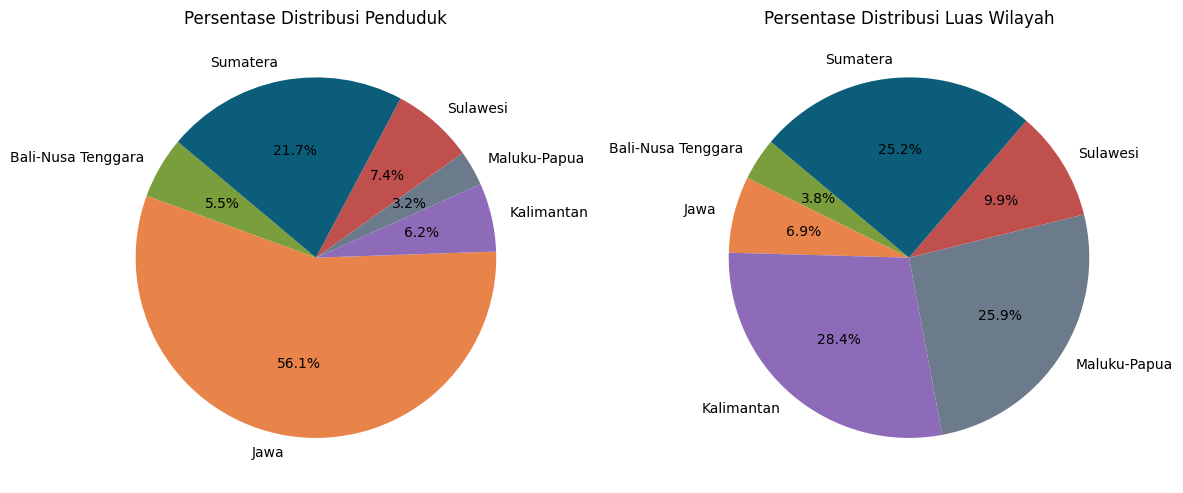

In [ ]:
# Agregasi data berdasarkan wilayah
wilayah_df = df.groupby("wilayah")[["penduduk", "luas"]].sum()

# Menghitung persentase
wilayah_persen = (wilayah_df / wilayah_df.sum() * 100).round(2)
display(wilayah_persen)

penduduk_jawa = wilayah_persen.loc["Jawa", "penduduk"]
luas_jawa = wilayah_persen.loc["Jawa", "luas"]

# Visualisasi perbandingan penduduk vs luas menggunakan Pie Chart berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Warna yang konsisten
colors_pie = [warna[w] for w in wilayah_persen.index]

ax1.pie(wilayah_persen["penduduk"], labels=wilayah_persen.index, autopct='%1.1f%%', colors=colors_pie, startangle=140)
ax1.set_title("Persentase Distribusi Penduduk")

ax2.pie(wilayah_persen["luas"], labels=wilayah_persen.index, autopct='%1.1f%%', colors=colors_pie, startangle=140)
ax2.set_title("Persentase Distribusi Luas Wilayah")

plt.tight_layout()
plt.show()

 Interpretasi <br>
Wilayah Jawa sangat mendominasi dengan dihuni oleh **56.11%** dari total penduduk Indonesia, padahal luas daratannya sangat terbatas yaitu hanya mencakup **2.72%** dari total luas wilayah ke-34 provinsi tersebut.

 Pertanyaan 3: Pilih bubble atau choropleth untukmenunjukkan bahwa Jawa padat.Jelaskan alasan jenis peta dan kelas warna yang Anda pilih.

In [ ]:
# Membuat peta Choropleth menggunakan Folium untuk menonjolkan kepadatan Jawa
peta_proyek = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")

# Menggunakan pembagian kelas (bins) khusus agar visualisasi kepadatan Jawa terlihat kontras
folium.Choropleth(
    geo_data=geo,
    data=df,
    columns=["kunci", "kepadatan"],
    key_on="feature.properties.kunci",
    bins=[0, 50, 150, 500, 1000, 16000],
    fill_color="YlOrRd",
    fill_opacity=0.85,
    line_opacity=0.3,
    nan_fill_color="#e0e0e0",
    legend_name="Kepadatan Penduduk (jiwa/km2)"
).add_to(peta_proyek)

peta_proyek

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning:

CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.



 Interpretasi <br>
 **Choropleth** dipilih karena jenis peta ini sangat efektif dalam merepresentasikan data intensitas wilayah (kepadatan penduduk) melalui gradasi warna langsung pada batas geografis resmi masing-masing provinsi. Kelas warna yang dipakai dirancang menggunakan skala kustom *0, 50, 150, 500, 1000, 16000* dengan palet **YlOrRd (Yellow-Orange-Red)** agar seluruh provinsi di Pulau Jawa yang memiliki kepadatan di atas 500-1000+ jiwa/km² langsung terarsir dengan warna merah pekat yang sangat kontras dibandingkan dengan pulau-pulau lain yang mayoritas berpenduduk jarang (berwarna kuning terang).

Jawaban Proyek Mini
1. Provinsi terpadat adalah **DKI Jakarta** (**15.904** jiwa/km2) dan paling jarang adalah **Papua** (**13** jiwa/km2), selisih sekitar **1.180** kali lipat.
2. Wilayah Jawa dihuni **56.11** % penduduk dengan luas hanya **2.72** % dari total 34 provinsi.
3. Saya memilih peta **Choropleth** karena **peta ini memvisualisasikan data rasio/kepadatan per unit area dengan batas wilayah yang jelas sehingga ketimpangan spasial langsung terlihat**. Kelas warna yang dipakai adalah **Yellow-Orange-Red dengan bins kustom** agar **provinsi-provinsi di Jawa terpetakan secara kontras dengan warna merah tua yang mencolok dibandingkan wilayah luar Jawa**.

# Latihan Mandiri

### Latihan 1: Perbandingan Gaya Peta Tiles
Membandingkan visualisasi marker menggunakan tiles `CartoDB positron` dan `CartoDB dark_matter`.

In [ ]:
# Membuat peta perbandingan dengan CartoDB positron
peta_latihan1_light = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")
for _, r_row in df.iterrows():
    folium.Marker(
        location=[r_row["lat"], r_row["lon"]],
        tooltip=r_row["provinsi"],
    ).add_to(peta_latihan1_light)

# Membuat peta perbandingan dengan CartoDB dark_matter
peta_latihan1_dark = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB dark_matter")
for _, r_row in df.iterrows():
    folium.Marker(
        location=[r_row["lat"], r_row["lon"], ],
        tooltip=r_row["provinsi"],
    ).add_to(peta_latihan1_dark)

display(peta_latihan1_light)
display(peta_latihan1_dark)

**Analisis Keterbacaan:**
* **`CartoDB positron` (Light Gaya):** Memberikan kontras yang sangat baik untuk marker berwarna biru standar bawaan Folium serta label teks berwarna gelap. Gaya ini sangat bersih dan cocok jika kita ingin menekankan informasi marker.
* **`CartoDB dark_matter` (Dark Gaya):** Membuat warna marker menyala lebih kontras secara visual (efek berpendar/neon). Namun, beberapa teks bawaan dasar laut atau kontur daratan yang berwarna abu-abu gelap menjadi lebih sulit terbaca jika tidak disesuaikan.

### Latihan 2: Peta Kerapatan (HeatMap)
Mengimplementasikan `HeatMap` berbasis jumlah penduduk dan menganalisis perbedaannya dengan peta bubble.

In [ ]:
from folium.plugins import HeatMap

peta_latihan2 = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")

# Menyiapkan data untuk HeatMap: [lat, lon, bobot/penduduk]
data_panas = df[["lat", "lon", "penduduk"]].values.tolist()

HeatMap(data_panas, radius=25, blur=15).add_to(peta_latihan2)
peta_latihan2

**Perbedaan HeatMap vs Peta Bubble:**
* **Peta Bubble:** Menampilkan kuantitas diskret pada titik lokasi koordinat yang presisi melalui ukuran radius lingkaran yang tegas, tanpa memengaruhi area di sekelilingnya.
* **HeatMap:** Menampilkan gradasi densitas atau kerapatan yang kontinu. Area dengan beberapa titik berdekatan (seperti Pulau Jawa) akan melebur menjadi satu wilayah zona merah yang intens, menciptakan visualisasi sebaran spasial yang mengalir/mulus.

### Latihan 3: Choropleth Penduduk (Jumlah Mentah) vs Kepadatan

In [ ]:
peta_latihan3 = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")

# Choropleth berdasarkan jumlah penduduk mentah
folium.Choropleth(
    geo_data=geo,
    data=df,
    columns=["kunci", "penduduk"],
    key_on="feature.properties.kunci",
    bins=[0, 2, 5, 10, 15, 50],
    fill_color="YlOrRd",
    fill_opacity=0.8,
    line_opacity=0.3,
    nan_fill_color="lightgray",
    legend_name="Jumlah Penduduk Mentah (juta jiwa)",
).add_to(peta_latihan3)

peta_latihan3

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning:

CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.



**Peta mana yang lebih menyesatkan?**

Peta **penduduk mentah (absolute count)** jauh lebih menyesatkan untuk peta bertipe Choropleth.
* **Alasannya:** Choropleth secara visual mengisi seluruh poligon area wilayah dengan warna penuh. Jika kita menggunakan angka mentah, provinsi dengan area sangat luas namun berpenduduk jarang akan diarsir dengan warna yang sama intensnya dengan daerah sempit yang padat, atau sebaliknya.
* Choropleth seharusnya selalu menampilkan nilai rasio terstandarisasi (seperti **kepadatan penduduk per km²**) agar aspek luas wilayah tidak mendistorsi interpretasi mata visual pengguna.

### Latihan 4: Eksperimen Bins Baru `[0, 100, 500, 20000]`

In [ ]:
peta_latihan4 = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")

folium.Choropleth(
    geo_data=geo,
    data=df,
    columns=["kunci", "kepadatan"],
    key_on="feature.properties.kunci",
    bins=[0, 100, 500, 20000],
    fill_color="YlOrRd",
    fill_opacity=0.8,
    line_opacity=0.3,
    nan_fill_color="lightgray",
    legend_name="Kepadatan penduduk (jiwa per km2) - Bins Lebih Sedikit",
).add_to(peta_latihan4)

peta_latihan4

**Perubahan Narasi dan Analisis Kelas yang Lebih Sedikit:**
* **Perubahan Cerita:** Dengan hanya 3 interval kelas besar, perbedaan granularitas antar-provinsi di luar Jawa menjadi hilang (hampir semuanya terlihat seragam berwarna kuning muda). Sementara itu, seluruh provinsi di Jawa langsung masuk ke kelas tertinggi berwarna merah tua karena batas bawah kelas terakhir sangat rendah (mulai 500 langsung diloncatkan ke 20.000).
* **Kelebihan Kelas Lebih Sedikit:** Peta menjadi jauh lebih sederhana, kontras hitam-putih (atau ekstrim merah-kuning) langsung terlihat, mempermudah audiens awam menangkap pesan utama bahwa "Jawa sangat padat dibanding luar Jawa".
* **Kekurangan Kelas Lebih Sedikit:** Menghilangkan detail dan variasi lokal penting (informasi bahwa Sumatera Utara/Bali lebih padat daripada Kalimantan/Papua menjadi tertutup dan dianggap sama saja).

### Latihan 5: Menyimpan, Mengunduh File Peta, dan MarkerCluster

In [ ]:
from folium.plugins import MarkerCluster
from google.colab import files

# Membuat peta interaktif dengan MarkerCluster sebagai bonus
peta_bonus = folium.Map(location=[-2.5, 118], zoom_start=5, tiles="CartoDB positron")
cluster_penanda = MarkerCluster().add_to(peta_bonus)

for _, r_row in df.iterrows():
    folium.Marker(
        location=[r_row["lat"], r_row["lon"]],
        tooltip=r_row["provinsi"],
    ).add_to(cluster_penanda)

# Menyimpan peta ke format html
peta4.save("peta.html")
peta_bonus.save("peta_cluster.html")

# Mengunduh berkas peta.html
try:
    files.download("peta.html")
    print("Proses pengunduhan peta.html diinisiasi.")
except Exception as e:
    print("Pengunduhan otomatis dilewati atau gagal:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Proses pengunduhan peta.html diinisiasi.
